# 5 · Your own data + interactive app

**What.** How to load your own stratigraphic column from a CSV, run the backstrip, and use the interactive app.

**Why.** The package is not tied to Taiwan: any 1-D column with ages, thicknesses, lithology fractions and water depths works.

**Input format** (`pybasinsubs/example_data/template/my_column_template.csv`, one row per unit, youngest first; last row = base of section):

| column | meaning |
|---|---|
| unit | name |
| age_top_Ma, age_top_err_Ma | age of the top of the unit and 1σ |
| age_base_Ma | age of the base (start of deposition); blank = top of the unit below |
| thickness_m, thickness_err_m | present thickness and 1σ |
| water_depth_m, water_depth_err_m | paleo-water depth at deposition and 1σ |
| f_<lithology> | fraction of each lithology (any name in the lithology table) |
| eroded | 1 if the unit is no longer present (thickness = estimated eroded thickness) |
| eroded_at_Ma, water_depth_at_erosion_m | when it was removed (blank = R convention) |
| sea_level_m, sea_level_err_m | optional; blank = Miller et al. (2020) |

Lithology constants (φ₀, *c*, grain density ρ_g, matrix conductivity k_m) come from `pybasinsubs.lithology.default_lithologies()`; add your own rows with `lithology_table(extra)`.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs import data_path
from pybasinsubs.column import read_column
from pybasinsubs.lithology import default_lithologies
from pybasinsubs.backstrip import backstrip
from pybasinsubs.plotting import geohistory
default_lithologies()

,phi0,phi0_err,C,C_err,rho_g,rho_g_err,k_m,source
name,,,,,,,,
mudstone,0.425305,0.019245,1502.024,44.32066,2649.00,43.43,1.98,Lai et al. (2022) PoFun.csv (fit to Taiwan mud...
sandstone_tw,0.373416,0.011402,2860.291,91.89712,2666.67,8.82,3.16,Lai et al. (2022) PoFun.csv (fit to Taiwan san...
marine_avg,0.663000,0.033150,1333.000,66.65000,2647.00,52.94,2.00,Lai et al. (2022) PoFun.csv (average marine se...
shale,0.630000,0.030000,1960.800,100.00000,2720.00,30.00,1.98,Sclater & Christie (1980): c=0.51 /km
sandstone,0.490000,0.030000,3703.700,200.00000,2650.00,20.00,3.16,Sclater & Christie (1980): c=0.27 /km
chalk,0.700000,0.030000,1408.500,80.00000,2710.00,20.00,2.90,Sclater & Christie (1980): c=0.71 /km
shaly_sandstone,0.560000,0.030000,2564.100,150.00000,2680.00,20.00,2.50,Sclater & Christie (1980): c=0.39 /km


In [3]:
col = read_column(data_path("template", "my_column_template.csv"), name="template (Sodir 30/4-1)")
col.units

,unit,age_top_Ma,age_top_err_Ma,age_base_Ma,thickness_m,thickness_err_m,water_depth_m,water_depth_err_m,f_shale,f_sandstone,f_chalk,eroded,sea_level_m,sea_level_err_m,eroded_at_Ma,water_depth_at_erosion_m
0,NORDLAND,0.0,0.0,15.0,777.0,15.54,120.5,10.0,0.70,0.30,0.0,0,-4.387273,2.562850,NaN,0.0
1,HORDALAND,18.0,2.0,54.0,997.0,19.94,300.0,150.0,0.85,0.15,0.0,0,-1.050959,0.727093,NaN,0.0
2,ROGALAND,54.0,1.0,66.0,343.0,6.86,400.0,200.0,0.80,0.20,0.0,0,39.804127,1.933284,NaN,0.0
3,SHETLAND,66.0,0.5,100.5,1664.0,33.28,500.0,250.0,0.80,0.00,0.2,0,52.175412,1.167175,NaN,0.0
4,CROMER KNOLL,100.5,1.0,140.0,461.0,9.22,400.0,200.0,0.70,0.00,0.3,0,0.000000,100.000000,NaN,0.0
5,VIKING,140.0,2.0,166.0,795.0,15.90,300.0,200.0,0.90,0.10,0.0,0,0.000000,100.000000,NaN,0.0
6,BRENT,166.0,1.5,171.0,218.0,5.00,25.0,25.0,0.30,0.70,0.0,0,0.000000,100.000000,NaN,0.0
7,DUNLIN,171.0,2.0,199.0,54.0,5.00,100.0,50.0,0.70,0.30,0.0,0,0.000000,100.000000,NaN,0.0
8,base (TD),199.0,2.0,199.0,0.0,0.00,100.0,50.0,1.00,0.00,0.0,0,0.000000,100.000000,NaN,0.0


saved image/nb5_template_geohistory.png


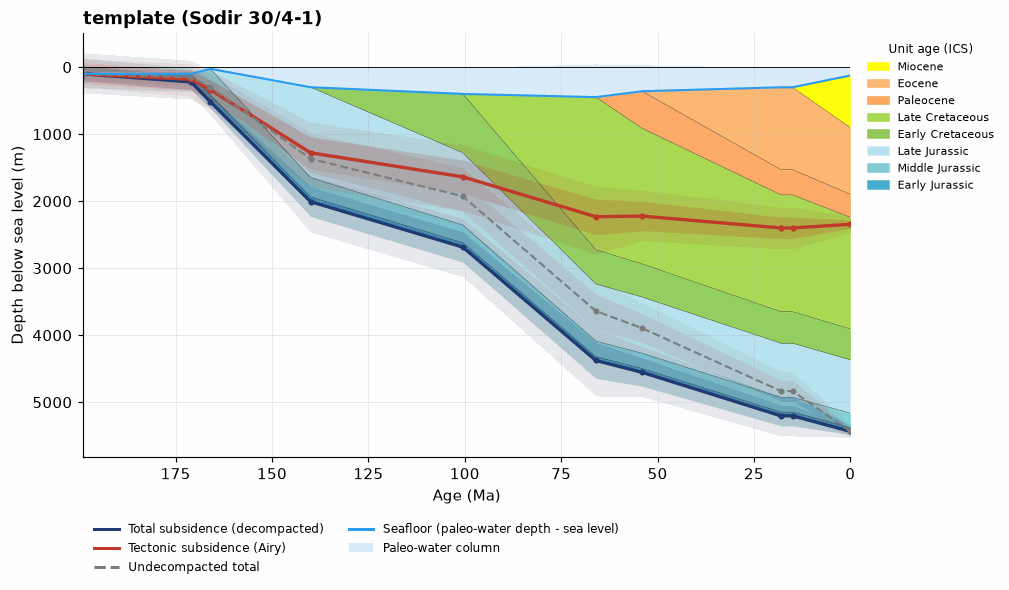

In [4]:
r = backstrip(col, n=1000)
fig, ax = plt.subplots(figsize=(9, 5)); geohistory(r, ax=ax, title=col.name)
save(fig, "nb5_template_geohistory.png"); plt.show()

**Reading.** Same layout as notebook 3. This template is the North Viking Graben well 30/4-1: tectonic subsidence (red) is steep during Jurassic rifting and then slows and flattens — the classic post-rift thermal subsidence shape that notebook 6 fits with McKenzie's model.

### Your own 2-D section (`flex2d.section_from_csv`)

A section uses the same template system as a 1-D column, split into two CSV files (examples in `pybasinsubs/example_data/template/`):

* **horizons** `my_section_horizons.csv`, one row per pick: `x_m` (distance along the line, m), `unit` (the unit whose **top** is picked), `depth_m` (m below sea level), optional `well`. The base of the oldest unit is the horizon `base`. The youngest unit's top is the present seafloor. A unit that is not picked at some x pinches out there.
* **units** `my_section_units.csv`, one row per unit, youngest first, the same columns as the 1-D template: `unit`, `age_top_Ma`, `age_base_Ma`, lithology fractions `f_<name>`, and optional `water_depth_m` (paleo-water depth at the end of deposition) and `sea_level_m`. Lithology and water depth are uniform along the line in this first version.
* **fault sticks** (optional) `my_section_faults.csv`: `fault_id, x, z` (m, z depth). The shallowest point of each stick is the fault's **upper tip**; the faults slip only horizons below it (here the base of the post-rift, 140 Ma).

`flex2d.section_to_csv` writes a Section back to the two tables (round trip).

In [5]:
from pybasinsubs import flex2d, app_core as core
t = flex2d.read_section_template()
display(pd.read_csv(t["horizons"]).head(4), pd.read_csv(t["units"]))
sec, fs = core.load_section(open(t["horizons"], "rb").read(), open(t["units"], "rb").read(), open(t["faults"], "rb").read())
print(f"{len(sec.units)} units x {len(sec.x)} columns ({sec.x[1] - sec.x[0]:g} m); faults:",
      [(f.label, f"{f.x0 / 1e3:.1f} km", f"{f.dip:.0f}°", f"tip {f.z_tip:.0f} m = top of {sec.units[f.tip_unit]}") for f in fs])

,well,x_m,unit,depth_m
0,NaN,1000.0,Pliocene-Recent,171.4
1,NaN,1500.0,Pliocene-Recent,182.9
2,NaN,2000.0,Pliocene-Recent,182.9
3,NaN,2500.0,Pliocene-Recent,182.9


,unit,age_top_Ma,age_base_Ma,f_shale,f_chalk,f_sandstone,f_shaly_sandstone,water_depth_m,sea_level_m
0,Pliocene-Recent,0.0,5.3,1.0,0.0,0.0,0.0,100.0,0.0
1,Miocene,5.3,23.0,1.0,0.0,0.0,0.0,150.0,0.0
2,Eocene-Oligocene,23.0,56.0,1.0,0.0,0.0,0.0,300.0,0.0
3,Palaeocene,56.0,66.0,1.0,0.0,0.0,0.0,400.0,0.0
4,Upper Cretaceous,66.0,100.5,0.0,1.0,0.0,0.0,200.0,0.0
5,Lower Cretaceous,100.5,140.0,1.0,0.0,0.0,0.0,300.0,0.0
6,Kimmeridgian-Ryazanian,140.0,157.3,1.0,0.0,0.0,0.0,400.0,0.0
7,Callovian-Oxfordian,157.3,166.1,1.0,0.0,0.0,0.0,200.0,0.0
8,Bajocian-Bathonian,166.1,170.3,0.0,0.0,1.0,0.0,50.0,0.0
9,Triassic-Lower Jurassic,170.3,252.0,0.0,0.0,0.0,1.0,0.0,0.0


10 units x 161 columns (500 m); faults: [('F1', '8.7 km', '27°', 'tip 1314 m = top of Kimmeridgian-Ryazanian'), ('F2', '19.9 km', '26°', 'tip 3073 m = top of Kimmeridgian-Ryazanian'), ('F3', '31.2 km', '23°', 'tip 3226 m = top of Kimmeridgian-Ryazanian'), ('F4', '43.8 km', '30°', 'tip 2882 m = top of Kimmeridgian-Ryazanian'), ('F5', '63.5 km', '27°', 'tip 2870 m = top of Kimmeridgian-Ryazanian')]


saved image/nb5_section_restored.png


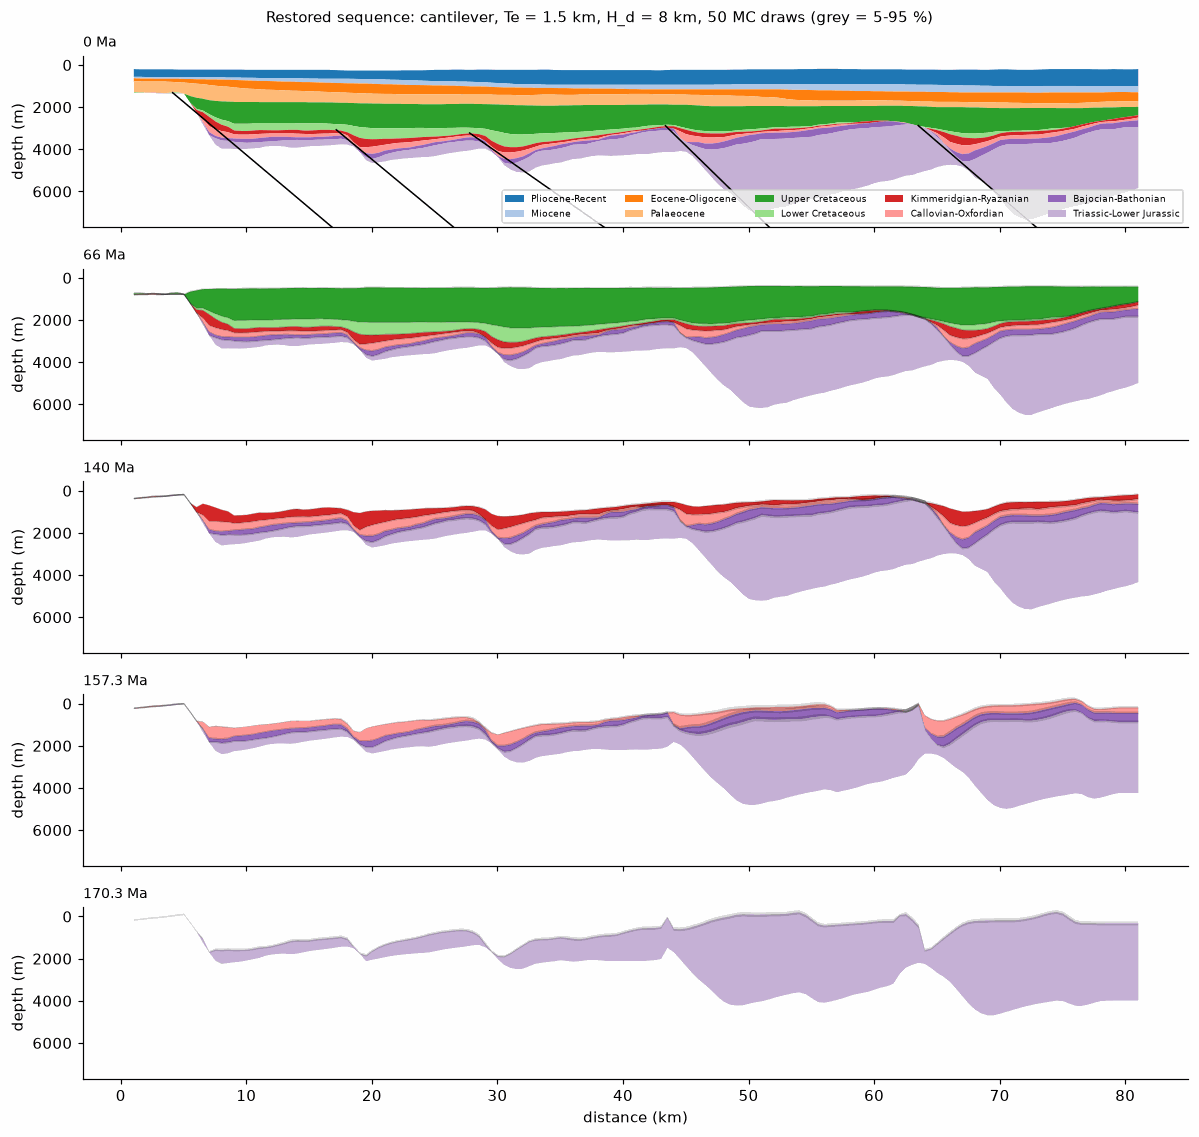

,age_Ma,mean_seafloor_m,seafloor_std_m,std,relief_p95_p5,max_relief,mean_fault_offset,roughness
0,0.0,199.0,19.0,19.0,69.0,80.0,10.0,7.0
1,5.0,292.0,24.0,24.0,79.0,88.0,12.0,5.0
2,23.0,323.0,28.0,28.0,90.0,122.0,13.0,7.0
3,56.0,368.0,30.0,30.0,106.0,150.0,28.0,9.0
4,66.0,446.0,79.0,79.0,313.0,405.0,24.0,24.0
5,100.0,733.0,174.0,174.0,534.0,736.0,148.0,52.0
6,140.0,653.0,281.0,281.0,872.0,1050.0,212.0,61.0
7,157.0,521.0,405.0,405.0,1161.0,1699.0,234.0,105.0
8,166.0,577.0,563.0,563.0,1714.0,2180.0,296.0,145.0
9,170.0,635.0,572.0,572.0,1711.0,2107.0,422.0,185.0


In [6]:
# The same call the 2-D tab of the app makes: restore with the cantilever model, Te 1.5 km, H_d 8 km, 50 MC draws
out = core.run_section(sec, fs, "cantilever", Te=1500.0, Hd=8e3, n_mc=50, seed=0, ages=[0, 66, 140, 157.3, 170.3])
save(out["fig"], "nb5_section_restored.png"); plt.show()
out["table"].round(0)

**Reading.** Each panel is the section restored to one age (grey bands: 5–95 % range of the unit tops over 50 Monte Carlo draws of porosity, compaction length and paleo-water depth, seed 0). The fault planes (top panel) start at their upper tip, the base of the post-rift, and do not cut the Cretaceous and younger units. The table lists the flatness metrics of the restored datum at each age (std, relief, residual fault offset); they are the numbers to compare when you change the method, T_e or H_d.

### Interactive app

The cell below shows the Panel app inline (needs a live kernel; in a static view you only see the last state). The same app runs as a web page with

```bash
pybasinsubs-ui                 # = panel serve pybasinsubs/apps/panel_app.py --show
pybasinsubs-ui --streamlit     # small Streamlit version
```

Tab **1-D column**: choose a data source (Coastal Range, a Sodir well, or upload your CSV), the lithology mixing rule, number of Monte Carlo draws, a scale factor on water depth, and an optional heat flow to see burial temperature and maturity.

Tab **2-D section**: upload a section (horizons + units CSV, below) and optional fault sticks, choose the method (backstrip only, cantilever, listric, domino), T_e, H_d and Monte Carlo draws, and view the restored sequence. Left blank, it runs the bundled Viking Graben template.

Tabs(sizing_mode='stretch_width')
    [0] Row(sizing_mode='stretch_width')
        [0] Column(width=320)
            [0] Markdown(str, sizing_mode='stretch_width')
            [1] Select(label='Data', name='Data', options=['Coastal Range N..., ...], sizing_mode='stretch_width', value='Coastal Range N...)
            [2] Select(label='Well', name='Well', options=['29/6-1', '30/4-1', ...], sizing_mode='stretch_width', value='29/6-1', visible=False)
            [3] FileInput(accept='.csv', sizing_mode='stretch_width', visible=False)
            [4] RadioButtonGroup(label='Mixing', name='Mixing', options=['paper', 'mixed'], sizing_mode='stretch_width', value='paper')
            [5] IntSlider(end=4000, label='Monte Carlo draws', name='Monte Carlo draws', sizing_mode='stretch_width', step=250, value=1000)
            [6] FloatSlider(end=1.5, label='Water-depth scale', name='Water-depth scale', sizing_mode='stretch_width', start=0.5, step=0.05, value=1.0)
            [7] FloatInput(label='Eroded thickness (m, ..., name='Eroded thickness (m, ..., sizing_mode='stretch_width')
            [8] IntSlider(end=120, label='Heat flow for maturity (m..., name='Heat flow for maturity (m..., sizing_mode='stretch_width')
            [9] Button(button_type='primary', color='primary', label='Run', name='Run', sizing_mode='stretch_width')
        [1] Column(sizing_mode='stretch_width')
            [0] Markdown(str, sizing_mode='stretch_width')
            [1] Tabs(sizing_mode='stretch_width')
                [0] Matplotlib(Figure, dpi=110, sizing_mode='stretch_width', tight=True)
                [1] Tabulator(disabled=True, height=300, sizing_mode='stretch_width', value=   node  age_Ma  ...)
                [2] Matplotlib(None, dpi=100, sizing_mode='stretch_width', tight=True)
    [1] Row(sizing_mode='stretch_width')
        [0] Column(width=320)
            [0] Markdown(str, sizing_mode='stretch_width')
            [1] FileInput(accept='.csv', label='Horizons CSV', name='Horizons CSV', sizing_mode='stretch_width')
            [2] FileInput(accept='.csv', label='Units CSV', name='Units CSV', sizing_mode='stretch_width')
            [3] FileInput(accept='.csv', label='Fault sticks CSV', name='Fault sticks CSV', sizing_mode='stretch_width')
            [4] Select(label='Method', name='Method', options=['backstrip (no faults)', ...], sizing_mode='stretch_width', value='cantilever')
            [5] FloatInput(label='Te (km)', name='Te (km)', sizing_mode='stretch_width', start=0.0, step=0.5, value=1.5)
            [6] FloatInput(label='H_d (km)', name='H_d (km)', sizing_mode='stretch_width', start=2.0, step=1.0, value=8.0)
            [7] IntInput(label='MC draws (0 = off)', name='MC draws (0 = off)', sizing_mode='stretch_width', start=0, step=10)
            [8] Checkbox(label='Re-place planes o..., name='Re-place planes o..., sizing_mode='stretch_width')
            [9] Button(button_type='primary', color='primary', label='Run section', name='Run section', sizing_mode='stretch_width')
        [1] Column(sizing_mode='stretch_width')
            [0] Markdown(str, sizing_mode='stretch_width')
            [1] Matplotlib(Figure, dpi=100, sizing_mode='stretch_width', tight=True)
            [2] Tabulator(disabled=True, height=280, sizing_mode='stretch_width', value=   age_Ma  mean_seafloor_m...)
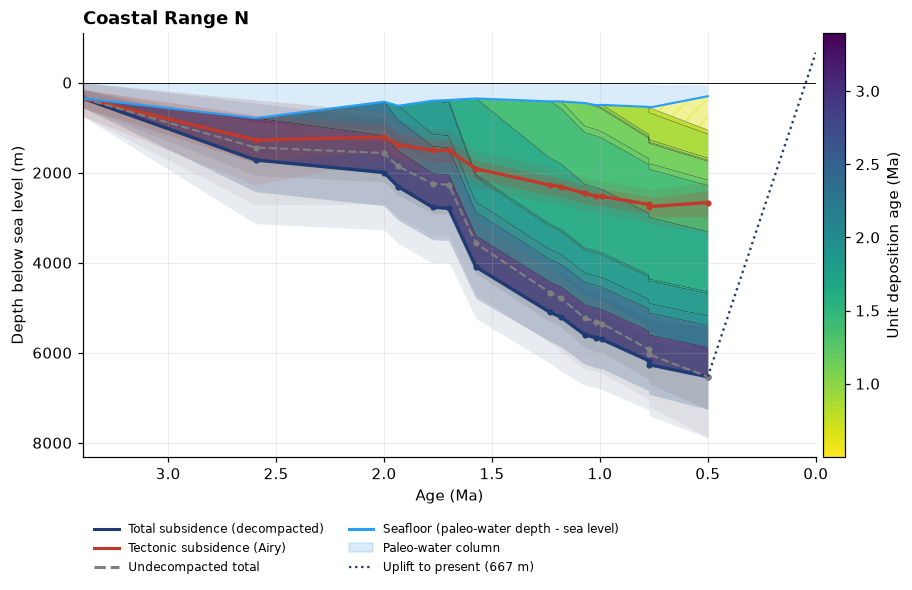
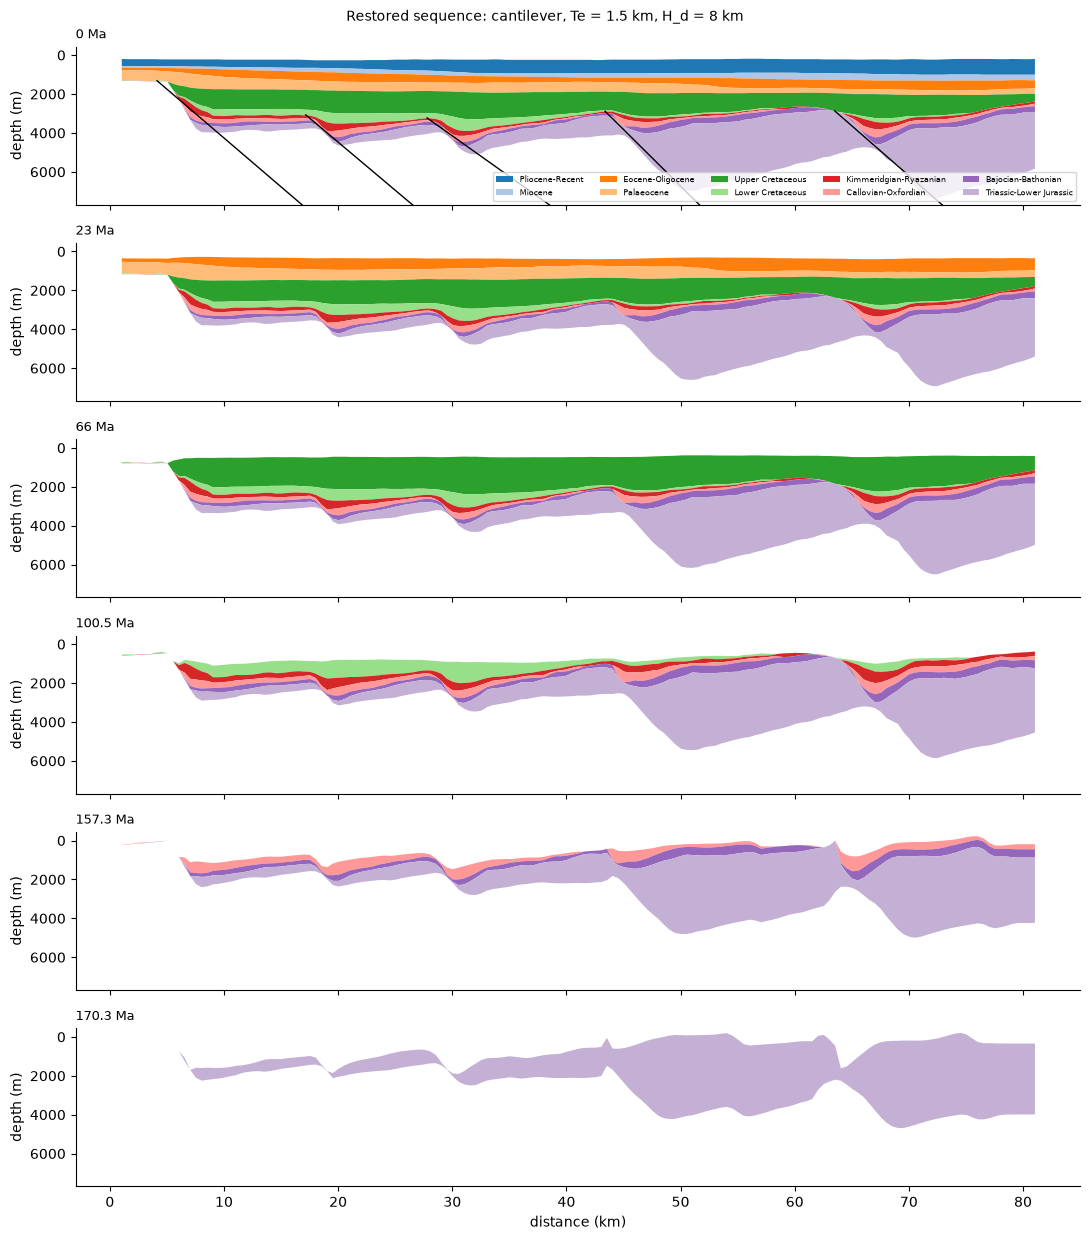

In [7]:
import panel as pn
from pybasinsubs.ui import app
pn.extension()
app()